Storm Chandra radiosonde tephigram (Valentia, 03953).

1. Get the sounding as text from the University of Wyoming archive
   (Region: Europe, Type: Text:List, station 03953, e.g. 27 Jan 2026 00Z).
2. Copy everything from the first dashed line down to the end of the station
   information block into a .txt file, and put its name in FILE below.
3. pip install metpy   (tephi draws the plot; MetPy does the calculations)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tephi
import metpy.calc as mpcalc
from metpy.units import units

In [5]:
FILE = "/home/ellen/git projects/phys-met/valentia_2026012700.csv"
TITLE = "Valentia (03953) 00 UTC 27 Jan 2026 - Storm Chandra"
 
 
def read_wyoming(path):
    """Read the fixed-width (7 chars per column) Wyoming TEXT:LIST table."""
    rows, dashes = [], 0
    with open(path) as f:
        for line in f:
            if line.startswith("-----"):
                dashes += 1
                continue
            if dashes < 2 or not line.strip():
                continue
            if any(c.isalpha() for c in line):  # reached "Station information"
                break
            vals = []
            for i in range(11):
                s = line[7 * i:7 * (i + 1)].strip()
                vals.append(float(s) if s else np.nan)
            rows.append(vals)
    return np.array(rows)
 
 
def read_wyoming_csv(path):
    """Read the new Wyoming server's CSV output, finding columns by name."""
    import pandas as pd
    df = pd.read_csv(path)
    print("CSV columns:", list(df.columns))
 
    def col(*words, avoid=()):
        for c in df.columns:
            name = c.lower()
            if all(w in name for w in words) and not any(a in name for a in avoid):
                return pd.to_numeric(df[c], errors="coerce").to_numpy()
        raise KeyError(f"No column containing {words} - check the printed names")
 
    p = col("pressure")
    T = col("temperature", avoid=("dew", "ice", "potential", "virtual"))
    Td = col("dew")
    drct = col("direction")
    speed_name = next(c for c in df.columns if "speed" in c.lower())
    spd = pd.to_numeric(df[speed_name], errors="coerce").to_numpy()
    if "m/s" in speed_name.lower():
        spd = spd * 1.94384  # m/s -> knots for the barbs
    return p, T, Td, drct, spd
 
 
if FILE.lower().endswith(".csv"):
    p_all, T_all, Td_all, drct_all, sknt_all = read_wyoming_csv(FILE)
else:
    data = read_wyoming(FILE)
    p_all, T_all, Td_all = data[:, 0], data[:, 2], data[:, 3]
    drct_all, sknt_all = data[:, 6], data[:, 7]


CSV columns: ['time', 'longitude', 'latitude', 'pressure_hPa', 'geopotential height_m', 'temperature_C', 'dew point temperature_C', 'ice point temperature_C', 'relative humidity_%', 'humidity wrt ice_%', 'mixing ratio_g/kg', 'wind direction_degree', 'wind speed_m/s']


In [6]:
# Sort from the surface upwards (highest pressure first)
order = np.argsort(-p_all)
p_all, T_all, Td_all = p_all[order], T_all[order], Td_all[order]
drct_all, sknt_all = drct_all[order], sknt_all[order]
 
# Keep levels with both T and Td, pressure strictly decreasing (MetPy needs this)
ok = ~np.isnan(p_all) & ~np.isnan(T_all) & ~np.isnan(Td_all)
p_v, T_v, Td_v = p_all[ok], T_all[ok], Td_all[ok]
keep = np.concatenate([[True], np.diff(p_v) < 0])
p_v, T_v, Td_v = p_v[keep], T_v[keep], Td_v[keep]
 
p = p_v * units.hPa
T = T_v * units.degC
Td = Td_v * units.degC


In [7]:
# ---- Calculations (surface-based parcel) ----
parcel = mpcalc.parcel_profile(p, T[0], Td[0]).to("degC")
lcl_p, lcl_T = mpcalc.lcl(p[0], T[0], Td[0])
lfc_p, lfc_T = mpcalc.lfc(p, T, Td, parcel)
el_p, el_T = mpcalc.el(p, T, Td, parcel)
cape, cin = mpcalc.cape_cin(p, T, Td, parcel)
 
Tw_sfc = mpcalc.wet_bulb_temperature(p[0], T[0], Td[0])
thw = mpcalc.wet_bulb_potential_temperature(p, T, Td)
the = mpcalc.equivalent_potential_temperature(p, T, Td)
# 850 hPa values (interpolated in log-p) - the usual level for theta_w maps
thw_850 = np.interp(np.log(850), np.log(p_v[::-1]), thw.to("degC").m[::-1])
the_850 = np.interp(np.log(850), np.log(p_v[::-1]), the.to("K").m[::-1])


In [8]:
def fmt(q, unit):
    return "n/a" if np.isnan(q.m) else f"{q.to(unit).m:.1f} {unit}"
 
 
print(TITLE)
print(f"Surface:  p={p[0].m:.0f} hPa  T={T[0].m:.1f} C  Td={Td[0].m:.1f} C")
print(f"LCL:      {fmt(lcl_p, 'hPa')}, {fmt(lcl_T, 'degC')}")
print(f"LFC:      {fmt(lfc_p, 'hPa')}, {fmt(lfc_T, 'degC')}")
print(f"EL:       {fmt(el_p, 'hPa')}, {fmt(el_T, 'degC')}")
print(f"CAPE:     {cape.m:.0f} J/kg")
print(f"CIN(E):   {cin.m:.0f} J/kg")
print(f"T_w sfc:  {fmt(Tw_sfc, 'degC')}")
print(f"theta_w:  sfc {thw[0].to('degC').m:.1f} C, 850 hPa {thw_850:.1f} C")
print(f"theta_e:  sfc {the[0].to('K').m:.1f} K, 850 hPa {the_850:.1f} K")


Valentia (03953) 00 UTC 27 Jan 2026 - Storm Chandra
Surface:  p=959 hPa  T=6.2 C  Td=4.8 C
LCL:      938.6 hPa, 4.5 degC
LFC:      639.4 hPa, -15.5 degC
EL:       635.7 hPa, -15.8 degC
CAPE:     0 J/kg
CIN(E):   -103 J/kg
T_w sfc:  5.5 degC
theta_w:  sfc 7.4 C, 850 hPa 7.8 C
theta_e:  sfc 298.5 K, 850 hPa 299.4 K


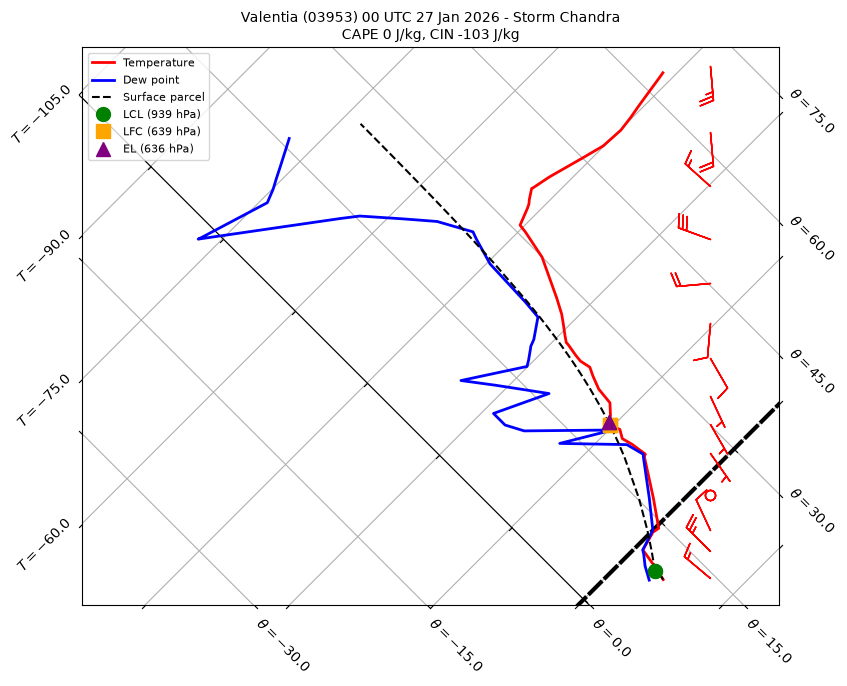

In [11]:
# ---- Tephigram ----
fig = plt.figure(figsize=(9, 9))
tpg = tephi.TephiAxes()
 
# Only draw the troposphere: the balloon reaches ~10 hPa, and plotting all of
# it squashes the interesting part into a corner. Calculations above still
# use the full profile.
P_TOP = 250  # hPa - raise to e.g. 400 to zoom in further, lower to 150 to see the tropopause
up = p_v >= P_TOP
temp_line = tpg.plot(list(zip(p_v[up], T_v[up])), color="red", linewidth=2,
                     label="Temperature")
tpg.plot(list(zip(p_v[up], Td_v[up])), color="blue", linewidth=2, label="Dew point")
tpg.plot(list(zip(p_v[up], parcel.m[up])), color="black", linestyle="--",
         label="Surface parcel")
 
 
def mark(pq, Tq, label, marker, colour):
    if not (np.isnan(pq.m) or np.isnan(Tq.m)):
        pt = (pq.to("hPa").m, Tq.to("degC").m)
        tpg.plot([pt, pt], marker=marker, markersize=10, linestyle="none",
                 color=colour, label=f"{label} ({pt[0]:.0f} hPa)")
 
 
mark(lcl_p, lcl_T, "LCL", "o", "green")
mark(lfc_p, lfc_T, "LFC", "s", "orange")
mark(el_p, el_T, "EL", "^", "purple")
 
# Wind barbs (speed in knots, direction, pressure)
w = ~np.isnan(drct_all) & ~np.isnan(sknt_all) & ~np.isnan(p_all)
pw, dw, sw = p_all[w], drct_all[w], sknt_all[w]
# High-resolution data has thousands of levels: keep one barb per ~50 hPa
targets = np.arange(1000, P_TOP - 1, -50)
idx = np.unique([np.argmin(np.abs(pw - t)) for t in targets if pw.min() <= t <= pw.max()])
try:
    temp_line.barbs(list(zip(sw[idx], dw[idx], pw[idx])))
except Exception as e:  # barbs are a nice extra, not essential
    print("Skipped wind barbs:", e)
 
plt.legend(loc="upper left", fontsize=8)
plt.title(f"{TITLE}\nCAPE {cape.m:.0f} J/kg, CIN {cin.m:.0f} J/kg", fontsize=10)
plt.savefig("chandra_tephigram.png", dpi=200, bbox_inches="tight")
plt.show()
 
